# Разбор упражнений к лекции 9

Условия — раздел 10 конспекта [`lecture09.md`](lecture09.md); краткие ответы без кода — [`exercises09.md`](exercises09.md). Все упражнения — домашние; семинар — ноутбук [`seminar09.ipynb`](seminar09.ipynb). **Сначала попробуйте сами**, потом сверяйтесь. Каждый разбор: условие → решение по пунктам → проверка кодом и картинка там, где она помогает. Нужен CasADi: `uv run --group casadi jupyter lab`; в Colab первая ячейка ставит его сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space
from l9helpers import *  # newton_lagrange, окружность, цепь на стержнях (собираются из build_demo09.py)

## 9.0. Разминка — счёт руками

**Условие.** *Суть: на квадратичной задаче с линейным ограничением один шаг даёт ответ.*

- (а) $\min\ \tfrac12\big(x_1^2+x_2^2\big)$ при $x_1+x_2=1$, $x\in\mathbb R^2$. Выпишите $F$ и матрицу ККТ $3\times3$.
- (б) Сделайте шаг метода Ньютона–Лагранжа из $x=(0,0)$, $\lambda=0$. Почему после него $F=0$?
- (в) Посчитайте тот же шаг способами null-space и range-space (§4).

**Решение.**

**(а)** Здесь $\nabla f=x$, $g=x_1+x_2-1$, $J=(1,\ 1)$, $\nabla^2g=0$. Поэтому $H=I$ при любом $\lambda$:

$$
F=\begin{pmatrix}x_1-\lambda\\ x_2-\lambda\\ x_1+x_2-1\end{pmatrix},\qquad
K=\begin{pmatrix}1&0&-1\\0&1&-1\\1&1&0\end{pmatrix}.
$$

**(б)** В точке $(0,0)$ при $\lambda=0$ невязка $F=(0,\ 0,\ -1)$. Система $K\,(p_1,p_2,\Delta\lambda)=(0,\ 0,\ 1)$ даёт $p_1=p_2=\Delta\lambda$ и $2\Delta\lambda=1$. Шаг $p=(0.5,\ 0.5)$, $\Delta\lambda=0.5$. В новой точке $F=(0,\ 0,\ 0)$.

Почему за один шаг: $f$ квадратичная, а $g$ линейная, поэтому $F$ линейна по $(x,\lambda)$. Линейная модель $F$ совпадает с самой $F$, и её нуль — точное решение.

**(в)** *Null-space.* $p_N=-J^\top(JJ^\top)^{-1}g=(1,1)\cdot\tfrac12=(0.5,\ 0.5)$. Базис касательной $Z=(1,-1)/\sqrt2$, правая часть $-Z^\top(\nabla f+Hp_N)=-Z^\top(0.5,\ 0.5)=0$, поэтому $u=0$. Множитель: $J^\top\lambda^+=Hp+\nabla f=(0.5,\ 0.5)$, то есть $\lambda^+=0.5$.

*Range-space.* $JH^{-1}J^\top=2$ и $JH^{-1}\nabla f-g=0+1=1$, поэтому $\lambda^+=0.5$. Затем $p=H^{-1}(J^\top\lambda^+-\nabla f)=(0.5,\ 0.5)$. Оба способа дают шаг из (б).

In [2]:
def kkt_00(x, lam):
    """Задача 9.0: f = 1/2 |x|^2, g = x1 + x2 - 1."""
    return x.copy(), np.array([[1.0, 1.0]]), np.eye(2), np.array([x[0] + x[1] - 1])

h = newton_lagrange(kkt_00, [0.0, 0.0], [0.0])
print("итерации:", [(x.round(3), lam.round(3), f"{nF:.0e}") for x, lam, nF in h])
assert len(h) - 1 == 1 and np.allclose(h[-1][0], [0.5, 0.5]) and np.isclose(h[-1][1][0], 0.5)

итерации: [(array([0., 0.]), array([0.]), '1e+00'), (array([0.5, 0.5]), array([0.5]), '0e+00')]


## 9.1. Шаг как квадратичная задача

**Условие.** *Суть: шаг Ньютона–Лагранжа решает задачу с квадратичной функцией и линейными ограничениями; на этом построен SQP.*

Докажите, что $p$ и $\lambda^+$ из §4 — решение и множитель задачи

$$
\min_{p\in\mathbb R^n}\ \nabla f^\top p+\tfrac12\,p^\top Hp\qquad\text{при}\qquad g+Jp=0 .
$$

**Решение.**

Функция Лагранжа задачи о шаге — с множителем $\mu\in\mathbb R^m$ и нашим знаком:

$$
\ell(p,\mu)=\nabla f^\top p+\tfrac12\,p^\top Hp-\mu^\top\big(g+Jp\big).
$$

Условие первого порядка лекции 8 — производная по $p$ равна нулю, и выполнено ограничение:

$$
\nabla f+Hp-J^\top\mu=0,\qquad g+Jp=0 .
$$

Это ровно система шага из §4: $Hp-J^\top\lambda^+=-\nabla f$ и $Jp=-g$, где $\mu=\lambda^+$.

У задачи о шаге ограничения линейны, а её якобиан — та же $J$. Её редуцированный гессиан — тот же $Z^\top HZ$. При условиях теоремы §3 система имеет единственное решение, и это строгий минимум задачи о шаге. Поэтому метод Ньютона–Лагранжа можно читать как «решай на каждом шаге квадратичную задачу с линейными ограничениями». Это и есть SQP (*sequential quadratic programming*, лекция 13).

## 9.2. Сломайте метод

**Условие.** (с кодом). *Суть: метод находит любое решение системы, в том числе максимум, а при вырожденной $K$ шага нет.*

- (а) Запустите метод на окружности §2.1 из разных стартов при $\lambda^{(0)}=0$. Найдите старт, из которого он приходит в дальнюю точку $(-0.894,\ -0.447)$.
- (б) Что будет при $\lambda^{(0)}=1$? Объясните теоремой §3.

**Решение.**

**(а)** Метод ищет решение системы, а у системы окружности два решения. Старт с другой стороны окружности приводит в дальнюю точку. Ячейка запускает метод из пяти стартов при $\lambda^{(0)}=0$ и рисует пути.

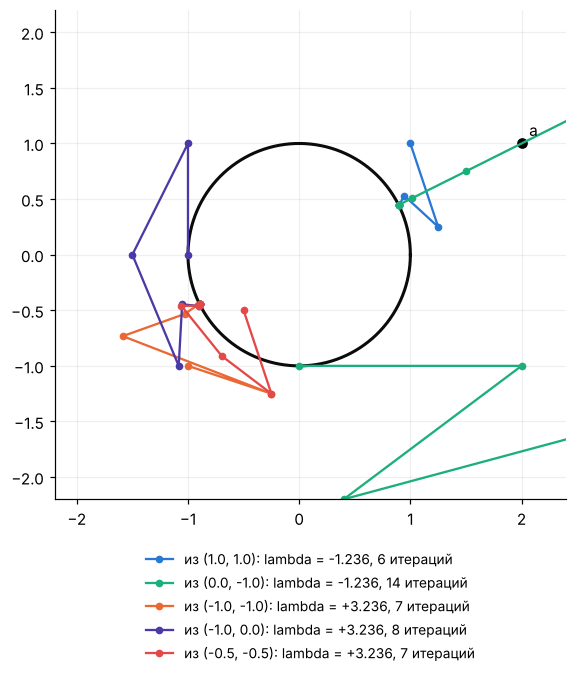

In [3]:
kk = circle_kkt(A_CIRCLE)
fig, ax = plt.subplots(figsize=(6, 6.2))
unit_circle(ax); ax.plot(*A_CIRCLE, "ko"); ax.annotate("a", A_CIRCLE, (5, 5), textcoords="offset points")
for x0, c in (([1.0, 1.0], BLUE), ([0.0, -1.0], AQUA), ([-1.0, -1.0], ORANGE), ([-1.0, 0.0], VIOLET), ([-0.5, -0.5], RED)):
    h = newton_lagrange(kk, x0, [0.0]); P = np.array([t[0] for t in h])
    ax.plot(P[:, 0], P[:, 1], "o-", ms=4, color=c, label=f"из {tuple(x0)}: lambda = {h[-1][1][0]:+.3f}, {len(h) - 1} итераций")
ax.set_aspect("equal"); ax.set_xlim(-2.2, 2.4); ax.set_ylim(-2.2, 2.2)
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.08)); plt.show()

Из стартов в левой нижней четверти метод приходит в дальнюю точку $(-0.894,\ -0.447)$ с $\lambda=3.236$. Это максимум расстояния до $a$. Метод сходится туда так же быстро: в максимуме $Z^\top HZ=1-\lambda=-2.236\ne0$, и матрица ККТ невырождена.

**(б)** При $\lambda^{(0)}=1$ гессиан $H=(1-\lambda)I=0$, и $\det K=(1-\lambda)(x_1^2+x_2^2)=0$ в любой точке (§3). Шаг не определён: `np.linalg.solve` сообщает о вырожденной матрице. По теореме: LICQ выполнено ($x\ne0$), но $Z^\top HZ=0$ не положителен.

In [4]:
try:
    newton_lagrange(kk, [1.0, 1.0], [1.0])
except np.linalg.LinAlgError as err:
    print("lambda(0) = 1:", err)

lambda(0) = 1: Singular matrix


## 9.3. Три способа на длинной цепи

**Условие.** (с кодом). *Суть: три способа дают один шаг, но решают системы разного размера.*

- (а) Цепь из $N$ грузов на $N+1$ стержнях: найдите $n$, $m$ и размеры трёх систем §4.3 при $N=3,\ 10,\ 40$.
- (б) При $N=40$ сделайте первый шаг из прямой $z=0$ тремя способами. Совпадают ли шаги?

**Решение.**

**(а)** У цепи из $N$ грузов переменных $n=2N$, стержней $m=N+1$. Размеры трёх систем §4.3:

| $N$ | вся $K$: $3N+1$ | range-space: $N+1$ | null-space: $N-1$ |
|---|---|---|---|
| 3 | 10 | 4 | 2 |
| 10 | 31 | 11 | 9 |
| 40 | 121 | 41 | 39 |

При $N=40$ стержень длины $5/41=0.122$ м. Range-space и null-space решают системы почти одного размера. Выигрыш null-space велик, только когда ограничений почти столько же, сколько переменных.

**(б)** Ячейка делает первый шаг тремя способами при $N=40$ и решает цепь до конца.

наименьшее собственное число H: 0.0576 ; ранг J: 41
расхождение шагов: null-space 3e-13, range-space 1e-13
метод Ньютона–Лагранжа: 13 итераций, |F| = 1e-12


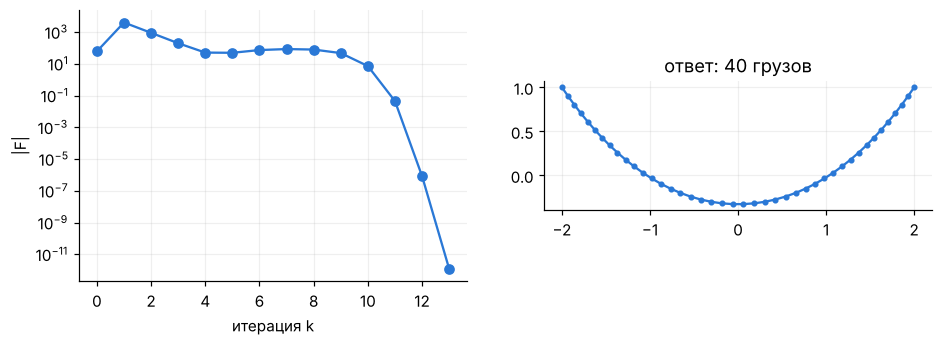

In [5]:
ch40 = rod_chain(N=40); ck40 = ch40["kkt"]; n, m = 80, 41
l0 = lam_ls(ck40, ch40["v0"], m)                               # множители по МНК
gf, J, H, g = ck40(ch40["v0"], l0)
print("наименьшее собственное число H:", round(np.linalg.eigvalsh(H).min(), 4), "; ранг J:", np.linalg.matrix_rank(J))
K = np.block([[H, -J.T], [J, np.zeros((m, m))]])
p_full = np.linalg.solve(K, -np.concatenate([gf - J.T @ l0, g]))[:n]                        # 121 x 121
pN = -J.T @ np.linalg.solve(J @ J.T, g); Z = null_space(J)                                   # Z: 80 x 39
p_null = pN + Z @ np.linalg.solve(Z.T @ H @ Z, -Z.T @ (gf + H @ pN))                          # 39 x 39
lp = np.linalg.solve(J @ np.linalg.solve(H, J.T), J @ np.linalg.solve(H, gf) - g)            # 41 x 41
p_rng = np.linalg.solve(H, J.T @ lp - gf)
print(f"расхождение шагов: null-space {np.abs(p_full - p_null).max():.0e}, range-space {np.abs(p_full - p_rng).max():.0e}")
h = newton_lagrange(ck40, ch40["v0"], l0)
print(f"метод Ньютона–Лагранжа: {len(h) - 1} итераций, |F| = {h[-1][2]:.0e}")
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.2))
ax.semilogy([t[2] for t in h], "o-", color=BLUE); ax.set_xlabel("итерация k"); ax.set_ylabel("|F|")
y, z = chain_xy(ch40, h[-1][0]); bx.plot(y, z, ".-", color=BLUE); bx.set_aspect("equal"); bx.set_title("ответ: 40 грузов")
plt.show()

Три шага совпадают до ошибок округления. Множители по МНК снова дают $H\succ0$, поэтому range-space применим. Метод сходится за 13 итераций. Старт далёк от ответа: первые шаги большие, и невязка сначала растёт. Последние три шага — обрыв, как у цепи из трёх грузов.

## 9.4. Скорость обобщённого Гаусса–Ньютона

**Условие.** (руками). *Суть: множитель ошибки равен $\lambda^\ast$.*

- (а) Повторите вывод §5 для точки $a$ внутри окружности, $0<\lVert a\rVert<1$. Чему равен множитель ошибки?
- (б) Почему метод тем медленнее, чем ближе $a$ к центру?

**Решение.**

**(а)** Вывод §5 не зависит от того, где лежит $a$. Повернём картинку: $x^\ast=(1,0)$, $a=(\lVert a\rVert,\ 0)$, $x^{(k)}\approx(1,\ e_k)$. Сдвиг вдоль касательной $(a-x^{(k)})^\top(-e_k,\ 1)\approx-\lVert a\rVert e_k$, и

$$
e_{k+1}\approx\big(1-\lVert a\rVert\big)\,e_k=\lambda^\ast e_k .
$$

Теперь $\lambda^\ast=1-\lVert a\rVert\in(0,1)$: множитель положителен, и ошибка уменьшается без смены знака.

**(б)** Чем ближе $a$ к центру, тем ближе $\lambda^\ast$ к единице, и тем медленнее метод. Невязка в ответе — расстояние $1-\lVert a\rVert$ — растёт, а выброшенное слагаемое $-\lambda I$ — кривизна окружности, умноженная на $\lambda$. При $a$ в центре точек минимума целая окружность, и метод не сдвигается вовсе.

In [6]:
for na in (0.8, 0.5, 0.2):
    a = np.array([0.8, 0.6]) * na                             # точка внутри окружности
    e = angle_err(ggn_circle(a, [0.6, 0.8], 30), a)
    print(f"|a| = {na}: lambda* = {1 - na:.1f}, e_(k+1)/e_k = {(e[6:9] / e[5:8]).round(3)}")

|a| = 0.8: lambda* = 0.2, e_(k+1)/e_k = [0.2 0.2 0.2]
|a| = 0.5: lambda* = 0.5, e_(k+1)/e_k = [0.5 0.5 0.5]
|a| = 0.2: lambda* = 0.8, e_(k+1)/e_k = [0.8 0.8 0.8]


## 9.5. Прямая по точкам

**Условие.** (с кодом). *Суть: в задачах подгонки невязки малы, и обобщённый Гаусс–Ньютон сходится быстро.*

Прямую на плоскости зададим уравнением $n_1t+n_2s=d$ с нормалью $n_1^2+n_2^2=1$. Переменные — $x=(n_1,n_2,d)\in\mathbb R^3$. Невязка точки $(t_i,s_i)$ — расстояние до прямой: $r_i=n_1t_i+n_2s_i-d$.

- (а) Сгенерируйте 30 точек около прямой с шумом $\sigma=0.1$ и $\sigma=1$ (`default_rng(2026)`). Решите задачу обобщённым Гауссом–Ньютоном и сравните число итераций.
- (б) Сравните ответ с собственным вектором матрицы разброса точек. Чему равен $\lambda^\ast$?

**Решение.**

Невязки $r_i=n_1t_i+n_2s_i-d$ линейны по $x$, поэтому $J_r^\top J_r$ — точный $\nabla^2f$. Обобщённый Гаусс–Ньютон выбрасывает только кривизну ограничения $-\lambda\nabla^2g=-2\lambda\operatorname{diag}(1,1,0)$.

**(а)** Ячейка генерирует 30 точек около прямой $s=0.5t+1$ при двух уровнях шума. Затем решает задачу двумя методами из одного старта: $n=(0,1)$, $d$ — среднее $s_i$.

sigma = 0.1: обобщённый Гаусс–Ньютон 5 итераций, Ньютон–Лагранж 5; lambda* = 0.1368 = s_min/2; s_min/s_max = 0.0013
sigma = 1.0: обобщённый Гаусс–Ньютон 13 итераций, Ньютон–Лагранж 5; lambda* = 10.9202 = s_min/2; s_min/s_max = 0.0995


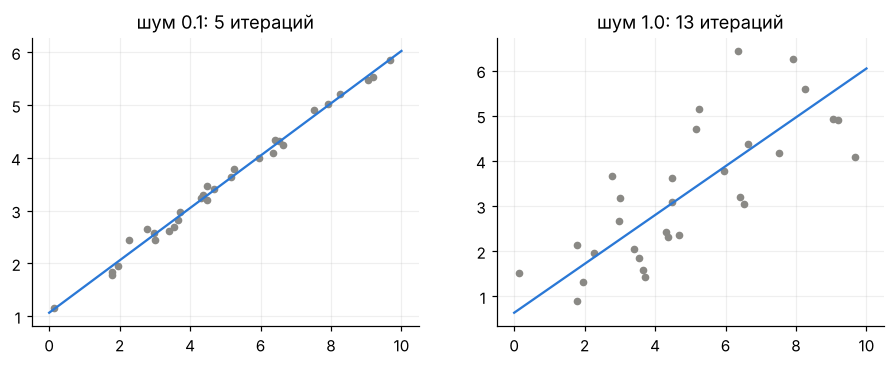

In [7]:
rng = np.random.default_rng(2026)
t = rng.uniform(0, 10, 30)                                    # абсциссы точек
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, sigma in zip(axes, (0.1, 1.0)):
    s = 0.5 * t + 1 + sigma * rng.standard_normal(30)         # точки около прямой
    Jr = np.column_stack([t, s, -np.ones(30)])                # якобиан невязок, 30 x 3

    def kkt_exact(x, lam):
        n1, n2, d = x
        return Jr.T @ (Jr @ x), np.array([[2 * n1, 2 * n2, 0.0]]), Jr.T @ Jr - lam[0] * np.diag([2.0, 2.0, 0.0]), np.array([n1**2 + n2**2 - 1])

    def kkt_ggn(x, lam):                                      # то же, но в матрице J_r^T J_r вместо H
        gf, J, _, g = kkt_exact(x, lam)
        return gf, J, Jr.T @ Jr, g

    x0 = np.array([0.0, 1.0, s.mean()])
    hg = newton_lagrange(kkt_ggn, x0, [0.0], maxit=200); hn = newton_lagrange(kkt_exact, x0, [0.0])
    P = np.column_stack([t, s]); C = (P - P.mean(0)).T @ (P - P.mean(0))   # матрица разброса 2 x 2
    ev, V = np.linalg.eigh(C); n_pca = V[:, 0] * np.sign(V[1, 0])
    x_g, lam_g = hg[-1][0], hg[-1][1][0]
    assert np.allclose(x_g[:2], n_pca, atol=1e-8) and np.isclose(lam_g, ev[0] / 2)
    print(f"sigma = {sigma}: обобщённый Гаусс–Ньютон {len(hg) - 1} итераций, Ньютон–Лагранж {len(hn) - 1}; "
          f"lambda* = {lam_g:.4f} = s_min/2; s_min/s_max = {ev[0] / ev[1]:.4f}")
    ax.plot(t, s, "o", ms=4, color=GRAY); tt = np.array([0, 10])
    ax.plot(tt, (x_g[2] - x_g[0] * tt) / x_g[1], color=BLUE); ax.set_title(f"шум {sigma}: {len(hg) - 1} итераций")
plt.show()

При шуме $0.1$ обобщённый Гаусс–Ньютон делает 5 итераций, как Ньютон–Лагранж. При шуме $1$ — уже 13, а Ньютон–Лагранж — по-прежнему 5.

**(б)** Ответ совпадает с собственным вектором матрицы разброса $C=\sum_i(p_i-\bar p)(p_i-\bar p)^\top$ для меньшего собственного числа $s_{\min}$. Здесь $p_i=(t_i,s_i)$, $\bar p$ — их среднее. При оптимальном $d=n^\top\bar p$ функция $f=\tfrac12n^\top Cn$, поэтому минимум на окружности $\lVert n\rVert=1$ — собственный вектор.

Множитель: умножим $\nabla f=J^\top\lambda$ скалярно на $x$. Слева $x^\top J_r^\top r=\lVert r\rVert^2$, справа $\lambda\,(2n_1^2+2n_2^2)=2\lambda$. Значит, $\lambda^\ast=\tfrac12\lVert r\rVert^2=f^\ast=s_{\min}/2$. Малый шум — малый $\lambda^\ast$, и метод почти ньютоновский. Множитель ошибки здесь — отношение $s_{\min}/s_{\max}$: $0.0013$ против $0.0995$.

## 9.6. Для желающих: знаки собственных чисел матрицы ККТ

**Условие.** *Суть: матрица ККТ знаконеопределена, поэтому солверы раскладывают её как $LDL^\top$.*

Сменим знак у $\lambda^+$, и матрица станет симметричной: $\begin{pmatrix}H&J^\top\\ J&0\end{pmatrix}$. Пусть выполнены LICQ и $Z^\top HZ\succ0$. Докажите, что у неё ровно $n$ положительных и $m$ отрицательных собственных чисел.

**Решение.**

Обозначим $K_s=\begin{pmatrix}H&J^\top\\ J&0\end{pmatrix}$ и $Y=J^\top(JJ^\top)^{-1}$ — матрицу $n\times m$, для которой $JY=I$. Столбцы $Z$ и $Y$ вместе дают базис $\mathbb R^n$: $JZ=0$, а $Y$ — комбинации строк $J$.

**Шаг 1. Смена базиса.** Возьмём невырожденную матрицу $T=\begin{pmatrix}Z&Y&0\\0&0&I\end{pmatrix}$ размера $(n+m)\times(n+m)$. Тогда

$$
T^\top K_sT=\begin{pmatrix}Z^\top HZ&Z^\top HY&0\\ Y^\top HZ&Y^\top HY&I\\ 0&I&0\end{pmatrix}.
$$

**Шаг 2. Убираем связь с первым блоком.** Блок $A=Z^\top HZ$ положительно определён. Вычтем из второй блочной строки первую, умноженную на $Y^\top HZA^{-1}$, и так же со столбцами. Получится блочно-диагональная матрица $\operatorname{diag}\Big(A,\ \begin{pmatrix}B&I\\ I&0\end{pmatrix}\Big)$, где $B=Y^\top HY-Y^\top HZA^{-1}Z^\top HY$.

**Шаг 3. Считаем знаки.** У $A$ ровно $n-m$ положительных собственных чисел. У $\begin{pmatrix}B&I\\ I&0\end{pmatrix}$ определитель $(-1)^m\ne0$ при любой $B$. Будем непрерывно уменьшать $B$ до нуля: собственные числа не проходят через ноль. При $B=0$ они равны $\pm1$, по $m$ штук. Итого $n-m+m=n$ положительных и $m$ отрицательных.

**Шаг 4. Переносим на $K_s$.** Все преобразования — вида $M\mapsto S^\top MS$ с невырожденной $S$. По закону инерции Сильвестра число положительных и отрицательных собственных чисел при этом не меняется. $\blacksquare$

Поэтому $K_s$ знаконеопределена при любой задаче с ограничениями, и разложение Холецкого к ней неприменимо. IPOPT проверяет эти числа после разложения $LDL^\top$. Если положительных меньше $n$, он прибавляет к $H$ матрицу $\delta I$.

In [8]:
ch = rod_chain(); ck = ch["kkt"]
h = newton_lagrange(ck, ch["v0"], lam_ls(ck, ch["v0"], 4))
_, J, H, _ = ck(*h[-1][:2])
Ks = np.block([[H, J.T], [J, np.zeros((4, 4))]])
ev = np.linalg.eigvalsh(Ks)
print("цепь в ответе: положительных", (ev > 0).sum(), "отрицательных", (ev < 0).sum(), " (n = 6, m = 4)")

цепь в ответе: положительных 6 отрицательных 4  (n = 6, m = 4)
